# moonshot_ml_sandbox — V1 feature-space visualization

**Goal.** Understand the *geometry* of the five-feature space **before** any
modelling. Not "do the features predict returns" (that waits for the first
regression) — just "what does this cloud of points actually look like?"

We climb a ladder, each rung a prerequisite for the next:

1. **Univariate** — the shape of each feature alone. Know your raw materials.
2. **Univariate over time** — coverage and whether a feature's distribution
   *drifts* across the years (non-stationarity).
3. **Bivariate** — which features secretly measure the same thing (correlation).
4. **Multivariate (PCA)** — squash the 5-D cloud onto a flat 2-D picture along
   the directions it's most spread out. This is the bridge into vector math.

**A subtlety that shapes every plot: raw vs z-scored.**
The dataset carries each feature twice — raw (`momentum_12_1`) and z-scored
(`momentum_12_1_z`). We use *both, for different questions*:
- **Raw** shows a feature's natural shape (skew, fat tails). Z-scoring hides this.
- **Z-scored** is the space the model actually sees, so all *geometry* (relations
  between features, the 5-D cloud) uses z-scored columns.

**The pooling trap (named so we avoid it).** The z-scores are computed
*per day*. Pooling all 3,756 days into one histogram *looks* mean-0-std-1, but
that's an artifact of stacking many daily normalizations, not a property of any
single day. So anything about *cross-sectional geometry* must be looked at
**within a single day**. Each section says which slice it uses and why.

This notebook writes nothing. It only reads the V1 dataset and draws.

## Cell 0 — Mount + load the V1 dataset (read-only)

In [1]:
from google.colab import drive
from pathlib import Path
drive.mount('/content/drive')

SANDBOX_DIR = Path("/content/drive/MyDrive/moonshot_ml_sandbox")
datasets = sorted(SANDBOX_DIR.glob("ml_sandbox_v1_dataset_*.parquet"))
assert datasets, f"No V1 dataset found in {SANDBOX_DIR} (build it first)."
DATASET_PATH = datasets[-1]
print(f"Loading (newest-wins, READ-ONLY): {DATASET_PATH.name}")

Mounted at /content/drive
Loading (newest-wins, READ-ONLY): ml_sandbox_v1_dataset_2026-09-07.parquet


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_parquet(DATASET_PATH)
df["date"] = pd.to_datetime(df["date"])

# The five features, raw and z-scored names side by side.
RAW = ["momentum_12_1", "reversal_1m", "realized_vol_60", "log_turnover", "overnight_drift"]
Z   = [f + "_z" for f in RAW]
NICE = {  # human labels for plot titles
    "momentum_12_1": "Momentum (12-1)",
    "reversal_1m": "Reversal (1m)",
    "realized_vol_60": "Realized vol (60d)",
    "log_turnover": "Log-turnover",
    "overnight_drift": "Overnight drift",
}

# --- figure export: save each figure AS IT IS MADE (before plt.show clears it)
# The end-of-notebook approach fails because plt.show() clears figures in a
# notebook, so a later cell sees no open figures. Saving at creation time works.
EXPORT_DIR = Path("/content/drive/MyDrive/moonshot_ml_sandbox/viz_exports")
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
_fig_counter = {"n": 0}
def save_fig(fig, name):
    _fig_counter["n"] += 1
    p = EXPORT_DIR / f"{_fig_counter['n']:02d}_{name}.png"
    fig.savefig(p, dpi=130, bbox_inches="tight")
    print(f"  [saved figure: {p.name}]")

print(f"{len(df):,} cards | {df['ticker'].nunique():,} tickers | "
      f"{df['date'].nunique():,} dates")
print(f"date range: {df['date'].min().date()} -> {df['date'].max().date()}")
print(f"\ncolumns: {df.columns.tolist()}")
print(f"\nfigures will be saved to: {EXPORT_DIR}")

1,813,407 cards | 1,041 tickers | 3,756 dates
date range: 2011-01-03 -> 2026-06-10

columns: ['ticker', 'date', 'momentum_12_1', 'reversal_1m', 'realized_vol_60', 'log_turnover', 'overnight_drift', 'fwd_ret_20d', 'mom_n_used', 'mom_n_full', 'rev_n_used', 'rev_n_full', 'momentum_12_1_z', 'reversal_1m_z', 'realized_vol_60_z', 'log_turnover_z', 'overnight_drift_z']

figures will be saved to: /content/drive/MyDrive/moonshot_ml_sandbox/viz_exports


## Section 1 — Univariate shapes: the five raw features, one at a time

**What we're doing.** A histogram of each *raw* feature pooled across all cards,
plus the summary numbers that actually matter. A histogram answers "what values
does this feature take, and how often?" — the single most basic thing to know
before reasoning about anything else.

**Numbers to read (and what they mean, plainly):**
- **median** — the middle value; half the cards are below it. More robust than the
  mean when tails are fat (and financial data always has fat tails).
- **skew** — is the distribution lopsided? 0 = symmetric. Positive = a long tail
  to the *right* (a few very large values). Realized-vol *must* be positively
  skewed (vol is floored at 0, can spike arbitrarily high).
- **excess kurtosis** — "fat-tailed-ness." 0 = normal-bell tails. Large positive =
  far more extreme values than a bell curve predicts. Returns are famously fat-
  tailed; if we *didn't* see this, something would be wrong.

**What healthy looks like:** momentum & reversal roughly centered near 0 with
tails; realized-vol strictly positive and right-skewed; log-turnover roughly
bell-shaped (that's *why* we logged it); overnight-drift tight around 0.

feature                   median        mean      skew  exc.kurt
----------------------------------------------------------------
momentum_12_1             0.0570      0.1647      3.38     35.03
reversal_1m               0.0028      0.0105      0.81      7.22
realized_vol_60           0.3431      0.3714      1.68      7.60
log_turnover             18.6948     18.5325     -0.35     -0.18
overnight_drift           0.0022      0.0023     -0.61     24.73
  [saved figure: 01_s1_raw_distributions.png]


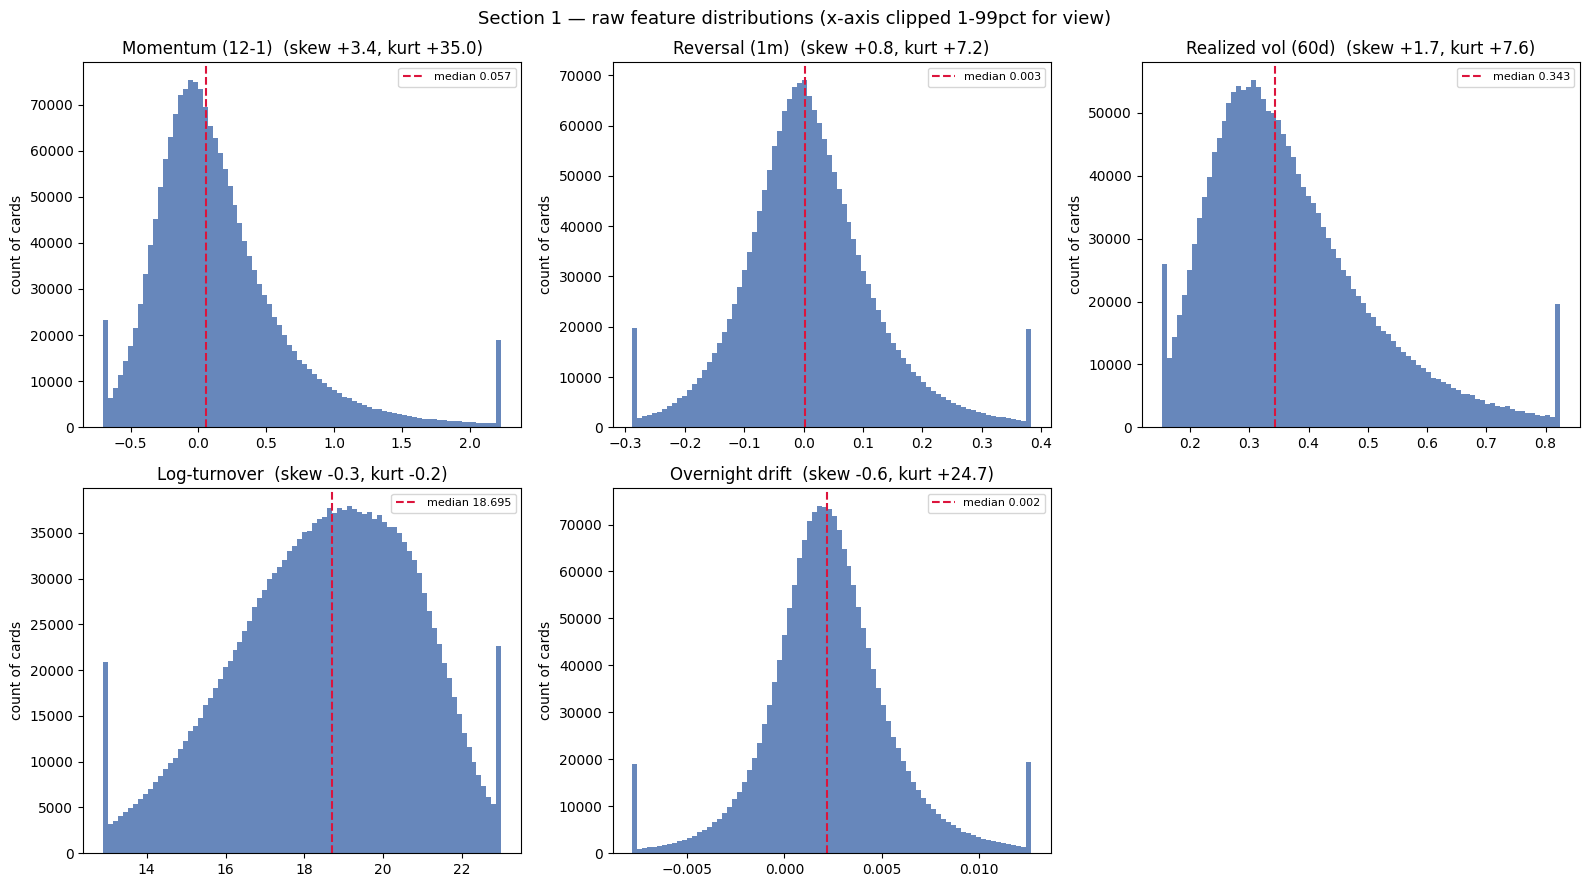

In [3]:
from scipy.stats import skew, kurtosis

# Winsorize ONLY for the x-axis view (so a handful of extremes don't squash the
# picture). The stats below are computed on the FULL unclipped data — we never
# hide the tails in the numbers, only in the plot's zoom.
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

print(f"{'feature':<20}{'median':>12}{'mean':>12}{'skew':>10}{'exc.kurt':>10}")
print("-" * 64)
for ax, f in zip(axes, RAW):
    x = df[f].dropna().to_numpy()
    med, mn = np.median(x), np.mean(x)
    sk, ku = skew(x), kurtosis(x)  # kurtosis() is EXCESS by default in scipy
    print(f"{f:<20}{med:>12.4f}{mn:>12.4f}{sk:>10.2f}{ku:>10.2f}")

    # clip to 1st-99th percentile for display only
    lo, hi = np.percentile(x, [1, 99])
    ax.hist(np.clip(x, lo, hi), bins=80, color="#4C72B0", alpha=0.85)
    ax.axvline(med, color="crimson", lw=1.5, ls="--", label=f"median {med:.3f}")
    ax.set_title(f"{NICE[f]}  (skew {sk:+.1f}, kurt {ku:+.1f})")
    ax.set_ylabel("count of cards")
    ax.legend(fontsize=8)

axes[-1].axis("off")  # 5 features, 6 panels — blank the last
fig.suptitle("Section 1 — raw feature distributions (x-axis clipped 1-99pct for view)",
             fontsize=13)
fig.tight_layout()
save_fig(fig, "s1_raw_distributions")
plt.show()

### 1b — The log lesson: why log-turnover, not raw turnover?

This is the single clearest "why we transform features" lesson in the dataset.
We didn't save raw turnover in V1, but we can reconstruct it: `turnover = exp(log_turnover)`.
Plot both side by side. Raw turnover spans so many orders of magnitude that its
histogram is a single spike at zero with an invisible tail stretching to the
right — useless. The log version is readable. *That contrast is the whole reason
we log heavily-skewed positive quantities.*

  [saved figure: 02_s1b_log_lesson.png]


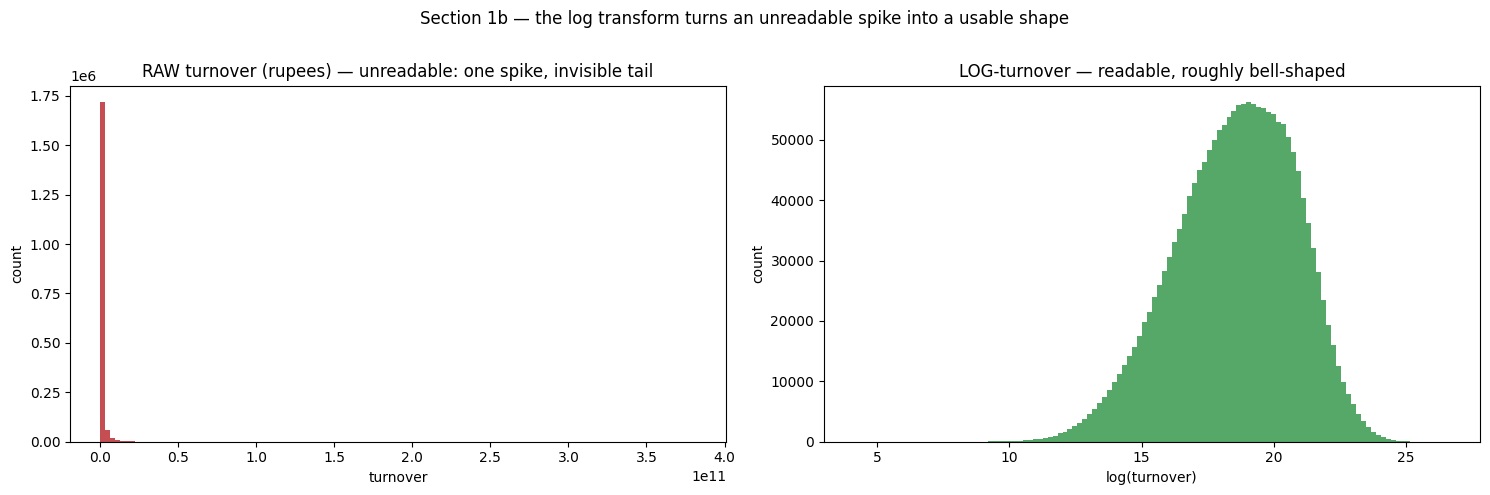

Raw turnover spans 6.12e+01 to 3.82e+11  (6.2e+09x range) — that's why we log it.


In [4]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5))

raw_turn = np.exp(df["log_turnover"].dropna().to_numpy())  # reconstruct rupee turnover
a1.hist(raw_turn, bins=120, color="#C44E52")
a1.set_title("RAW turnover (rupees) — unreadable: one spike, invisible tail")
a1.set_xlabel("turnover"); a1.set_ylabel("count")
a1.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))

a2.hist(df["log_turnover"].dropna(), bins=120, color="#55A868")
a2.set_title("LOG-turnover — readable, roughly bell-shaped")
a2.set_xlabel("log(turnover)"); a2.set_ylabel("count")

fig.suptitle("Section 1b — the log transform turns an unreadable spike into a usable shape",
             fontsize=12)
fig.tight_layout(); save_fig(fig, "s1b_log_lesson"); plt.show()

print("Raw turnover spans "
      f"{raw_turn.min():.2e} to {raw_turn.max():.2e}  "
      f"({raw_turn.max()/max(raw_turn.min(),1):.1e}x range) — that's why we log it.")

## Section 2 — Univariate over time: coverage and non-stationarity

Two questions a panel dataset always demands:

**2a — Coverage.** How many names per date, across the calendar? You saw
min 31 / median 488 as summary numbers; *seeing* it over time shows *where* the
thin patches sit (expect early 2011 warm-up; watch for the 2014 / 2025 dips your
main project flagged).

**2b — Non-stationarity.** Is "momentum in 2011" the same distribution as
"momentum in 2024"? We plot each raw feature's yearly median and its 10th-90th
percentile band. If the band *drifts or changes width* over time, the feature is
**non-stationary** — its meaning shifts across regimes. This is one of the most
important and uncomfortable facts in quant modelling: a model fit on one regime
may not transfer to another. Better to meet it now than to be ambushed by it.

  [saved figure: 03_s2a_coverage.png]


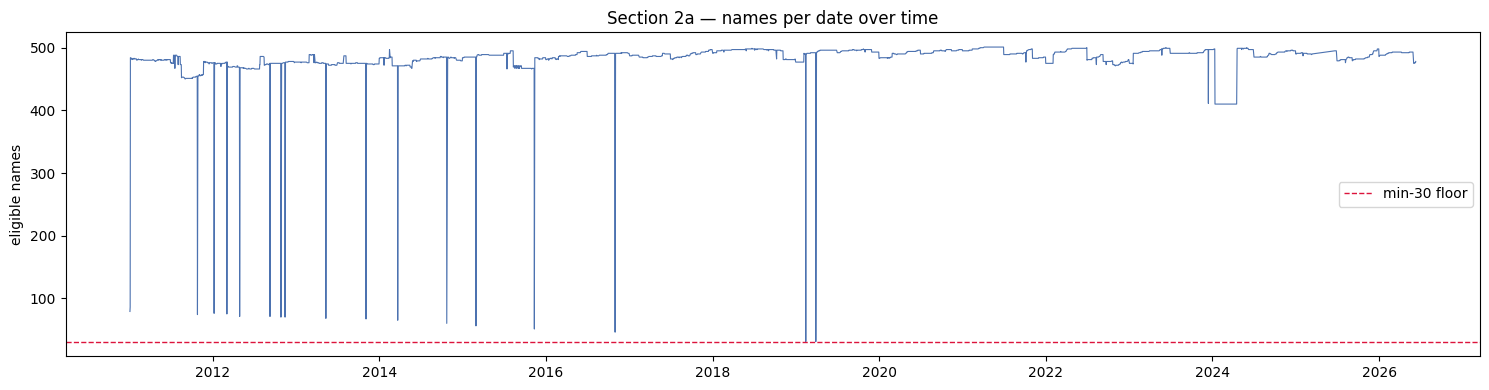

coverage: min 31 on 2019-02-13, median 488, max 501


In [5]:
# 2a — coverage over time
per_date = df.groupby("date").size()
fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(per_date.index, per_date.values, lw=0.8, color="#4C72B0")
ax.axhline(30, color="crimson", ls="--", lw=1, label="min-30 floor")
ax.set_title("Section 2a — names per date over time")
ax.set_ylabel("eligible names"); ax.legend()
fig.tight_layout(); save_fig(fig, "s2a_coverage"); plt.show()
print(f"coverage: min {per_date.min()} on {per_date.idxmin().date()}, "
      f"median {int(per_date.median())}, max {per_date.max()}")

  [saved figure: 04_s2b_nonstationarity.png]


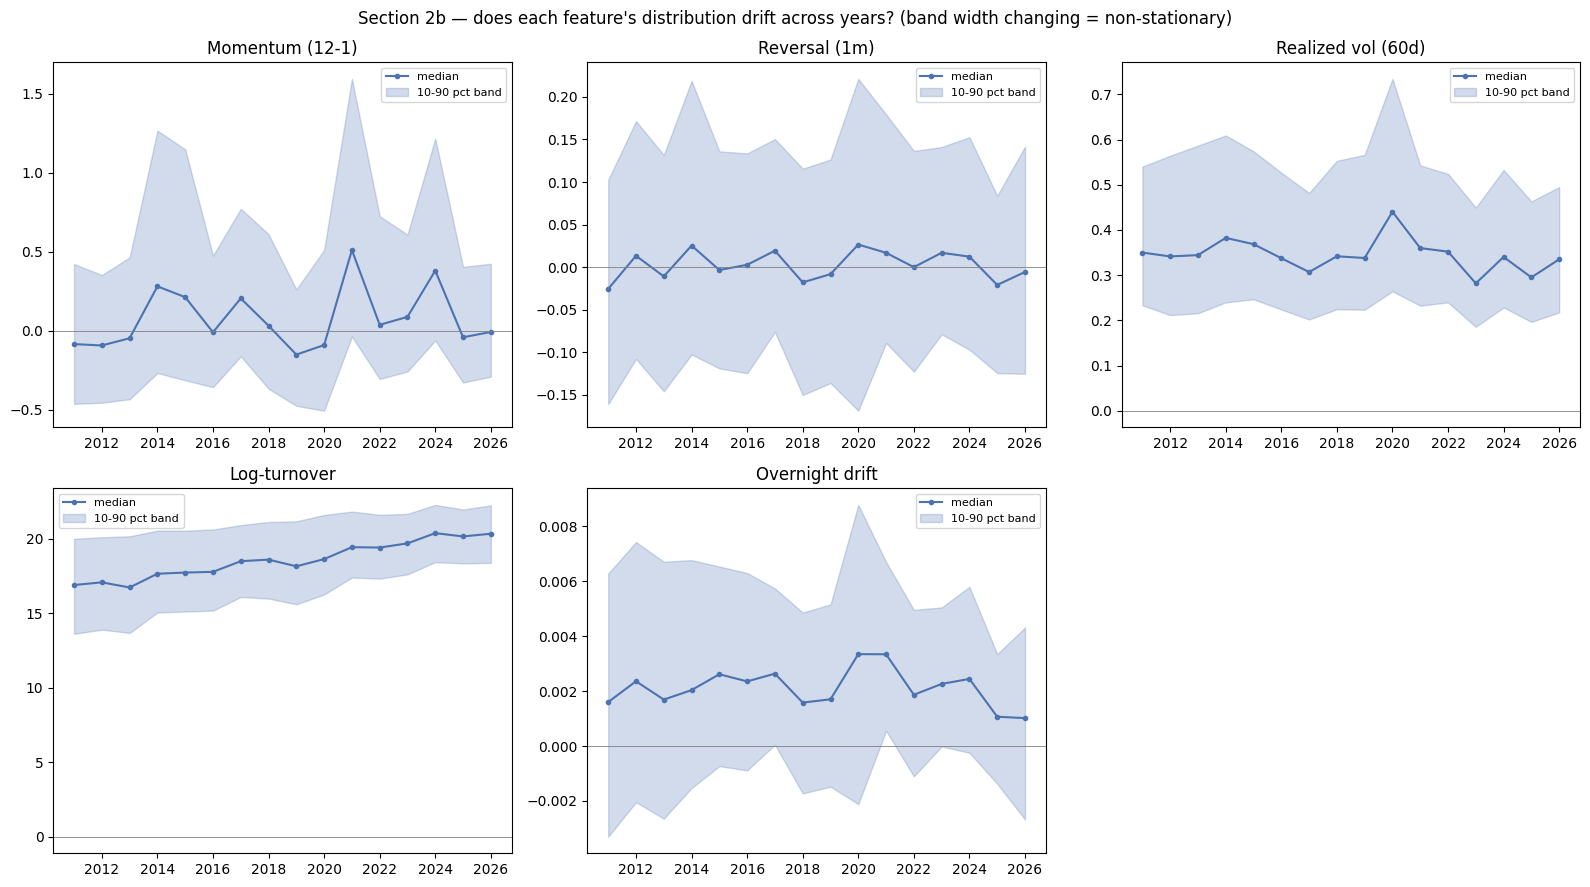

In [6]:
# 2b — yearly distribution of each RAW feature (median + 10-90 band)
df["year"] = df["date"].dt.year
fig, axes = plt.subplots(2, 3, figsize=(16, 9)); axes = axes.flatten()
for ax, f in zip(axes, RAW):
    g = df.groupby("year")[f]
    med = g.median()
    p10 = g.quantile(0.10); p90 = g.quantile(0.90)
    ax.plot(med.index, med.values, color="#4C72B0", marker="o", ms=3, label="median")
    ax.fill_between(med.index, p10.values, p90.values, alpha=0.25,
                    color="#4C72B0", label="10-90 pct band")
    ax.axhline(0, color="grey", lw=0.6)
    ax.set_title(NICE[f]); ax.legend(fontsize=8)
axes[-1].axis("off")
fig.suptitle("Section 2b — does each feature's distribution drift across years? "
             "(band width changing = non-stationary)", fontsize=12)
fig.tight_layout(); save_fig(fig, "s2b_nonstationarity"); plt.show()

## Section 3 — Bivariate: which features secretly measure the same thing?

**Why this is the highest-information view in the notebook.** If two of your five
features are strongly correlated, your "5-dimensional space" is really more like
4-D — the two redundant features占 the same direction. That directly limits what
any model can extract, and it's worth knowing *before* you fit anything.

**3a — Correlation heatmap.** The 5x5 matrix of correlations between the *z-scored*
features. We use z-scored (the space the model sees) and — to avoid the pooling
trap — we compute the correlation **within each day, then average across days**.
That gives the honest *cross-sectional* correlation, not one contaminated by
mixing regimes. Read it like this: near 0 = independent (good, they carry
different information); near +/-1 = redundant (they're the same axis).

**Your main project found momentum and realized-vol are entangled.** Watch that
cell specifically — do we reproduce it here on this independent build?

**3b — Scatter for the most-correlated pair.** A single correlation number hides
the *shape*. Two pairs can share correlation 0.4 yet look completely different —
one a clean tilt, one a fanning cloud. So we scatter the strongest pair (on one
representative day, to stay honest about the cross-section) and look at the shape.

  [saved figure: 05_s3a_corr_heatmap.png]


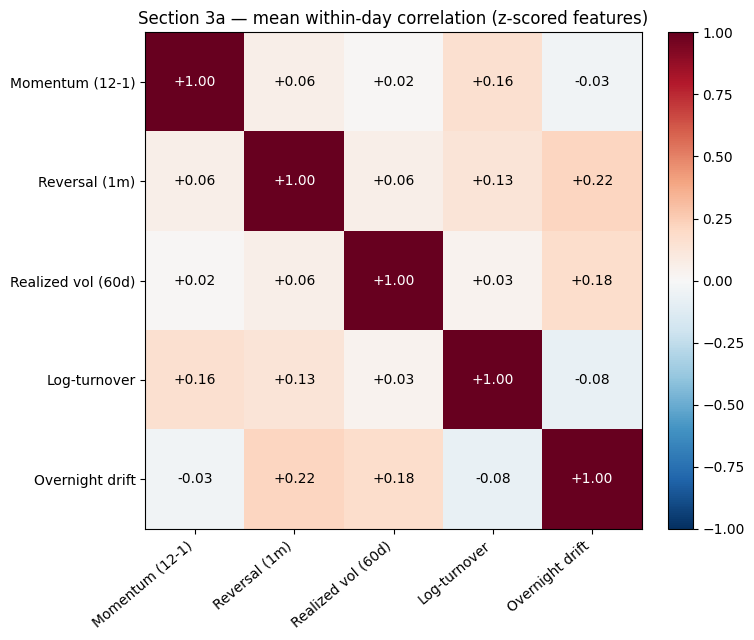

Off-diagonal pairs by |correlation|:
  Reversal (1m)        <-> Overnight drift      : +0.22
  Realized vol (60d)   <-> Overnight drift      : +0.18
  Momentum (12-1)      <-> Log-turnover         : +0.16
  Reversal (1m)        <-> Log-turnover         : +0.13
  Log-turnover         <-> Overnight drift      : -0.08
  Reversal (1m)        <-> Realized vol (60d)   : +0.06
  Momentum (12-1)      <-> Reversal (1m)        : +0.06
  Realized vol (60d)   <-> Log-turnover         : +0.03
  Momentum (12-1)      <-> Overnight drift      : -0.03
  Momentum (12-1)      <-> Realized vol (60d)   : +0.02

Strongest pair: Reversal (1m) <-> Overnight drift (+0.22)


In [7]:
# 3a — within-day correlation of z-scored features, averaged across days.
def daily_corr_mean(frame, cols):
    mats = []
    for _, day in frame.groupby("date"):
        if len(day) >= 30:                 # only well-populated days
            mats.append(day[cols].corr().to_numpy())
    return np.nanmean(np.stack(mats), axis=0)

corr = daily_corr_mean(df, Z)
labels = [NICE[f] for f in RAW]

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(5)); ax.set_yticks(range(5))
ax.set_xticklabels(labels, rotation=40, ha="right"); ax.set_yticklabels(labels)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{corr[i,j]:+.2f}", ha="center", va="center",
                color="white" if abs(corr[i,j]) > 0.5 else "black", fontsize=10)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_title("Section 3a — mean within-day correlation (z-scored features)")
fig.tight_layout(); save_fig(fig, "s3a_corr_heatmap"); plt.show()

# report the strongest off-diagonal pair
off = [(abs(corr[i, j]), i, j) for i in range(5) for j in range(i+1, 5)]
off.sort(reverse=True)
_, bi, bj = off[0]
print("Off-diagonal pairs by |correlation|:")
for a, i, j in off:
    print(f"  {NICE[RAW[i]]:<20} <-> {NICE[RAW[j]]:<20} : {corr[i,j]:+.2f}")
print(f"\nStrongest pair: {NICE[RAW[bi]]} <-> {NICE[RAW[bj]]} ({corr[bi,bj]:+.2f})")

  [saved figure: 06_s3b_strongest_scatter.png]


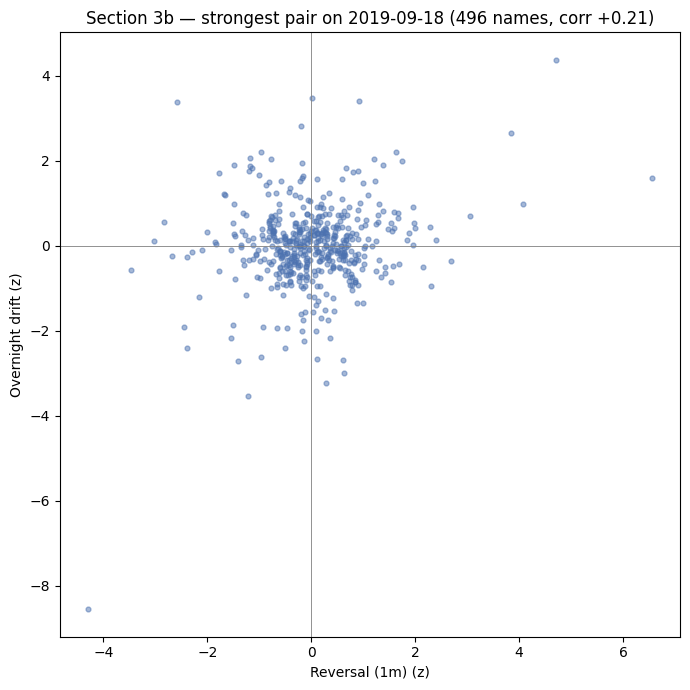

A tilted cigar = linear redundancy. A round blob = independent. A fan = relationship whose strength varies. Read the SHAPE, not just the number.


In [8]:
# 3b — scatter the strongest pair on ONE representative day (honest cross-section)
rep_day = per_date[per_date >= 480].index[len(per_date[per_date>=480])//2]  # a well-populated mid day
day = df[df["date"] == rep_day]
fx, fy = Z[bi], Z[bj]

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(day[fx], day[fy], s=12, alpha=0.5, color="#4C72B0")
ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
ax.set_xlabel(f"{NICE[RAW[bi]]} (z)"); ax.set_ylabel(f"{NICE[RAW[bj]]} (z)")
ax.set_title(f"Section 3b — strongest pair on {rep_day.date()} "
             f"({len(day)} names, corr {day[[fx,fy]].corr().iloc[0,1]:+.2f})")
fig.tight_layout(); save_fig(fig, "s3b_strongest_scatter"); plt.show()
print("A tilted cigar = linear redundancy. A round blob = independent. "
      "A fan = relationship whose strength varies. Read the SHAPE, not just the number.")

## Section 4 — The multivariate squash: PCA, built from scratch

**The problem.** The five z-scored features place every stock-day at a point in a
5-dimensional space. We can't draw 5-D. We want a flat 2-D picture that keeps as
much of the cloud's *shape* as possible.

**The idea, in plain terms.** Imagine the 5-D cloud of points has a shape — it's
longer in some directions than others. PCA finds the direction the cloud is *most*
stretched along (call it PC1), then the most-stretched direction *perpendicular*
to that (PC2), and so on. Plotting the cloud along PC1 and PC2 shows you the
"widest photograph" of it — the view that loses the least.

**Why this IS the vector math you want to learn.** Every word above is linear
algebra: the "directions" are *eigenvectors* of the feature covariance matrix,
how-stretched is the *eigenvalue*, and projecting a point onto PC1/PC2 is a *dot
product*. We build it with numpy step by step — covariance -> eigen-decomposition
-> projection — so you see the machinery, then cross-check against sklearn.

**The number that matters: "variance explained."** Each principal direction
accounts for some fraction of the cloud's total spread. If PC1 and PC2 together
explain most of it, your five features really encode only ~2 independent things —
which should agree with what the correlation heatmap hinted. If the variance is
spread evenly across all five PCs, the features are genuinely five different
things. Either answer is informative.

**Honesty about the slice.** PCA on the cross-sectional geometry must be done
within a day (the pooling trap again). We run it on our four chosen days — one
calm, one crisis (COVID, March 2020), two random — and compare. If the cloud's
shape *changes* between calm and crisis, that's a real regime effect you'll want
to remember when modelling.

  [saved figure: 07_s4_pca_fourday.png]


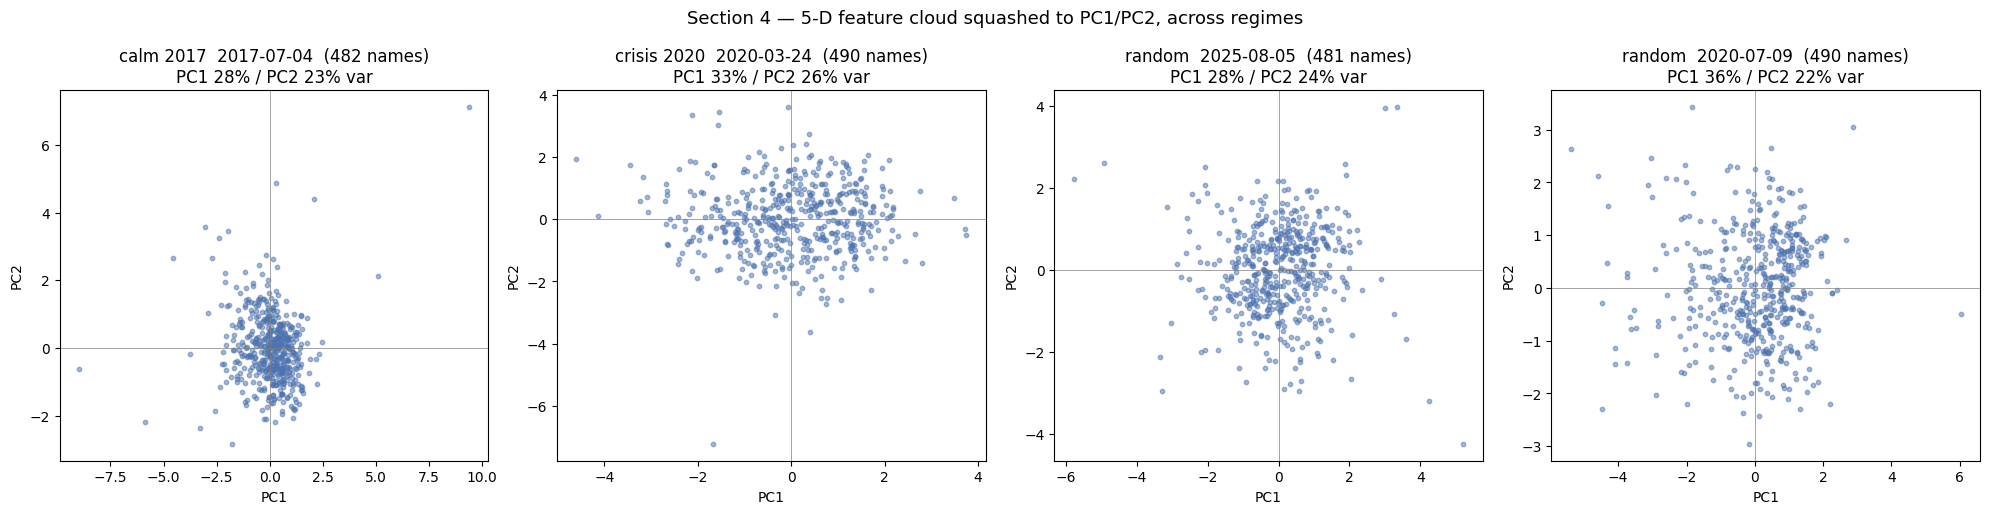

In [9]:
# --- PCA from scratch, on the z-scored features of a single day ---------------
def pca_from_scratch(X):
    # X: (n_points, 5) already z-scored. Returns (scores, explained_var_ratio, eigvecs).
    # Built explicitly so every step is visible.
    # 1. centre (z-scored per-day is already ~centred, but do it honestly)
    Xc = X - X.mean(axis=0)
    # 2. covariance matrix (5x5): how each feature co-varies with each other
    cov = np.cov(Xc, rowvar=False)
    # 3. eigen-decomposition: directions (eigvecs) + how-stretched (eigvals)
    eigvals, eigvecs = np.linalg.eigh(cov)      # eigh: symmetric matrix
    order = np.argsort(eigvals)[::-1]           # largest variance first
    eigvals, eigvecs = eigvals[order], eigvecs[:, order]
    # 4. project points onto the eigen-directions (dot product) = PCA scores
    scores = Xc @ eigvecs
    # 5. fraction of total spread each direction explains
    evr = eigvals / eigvals.sum()
    return scores, evr, eigvecs

# choose the four days: calm, crisis, two random (reproducible)
rng = np.random.default_rng(7)
well_pop = per_date[per_date >= 400].index
crisis = pd.Timestamp("2020-03-24")           # near the COVID trough
# nearest available date to the crisis target
crisis = min(well_pop, key=lambda d: abs((d - crisis).days))
# a calm day: lowest-vol year-end-ish; pick a 2017 mid date that's well populated
calm_candidates = [d for d in well_pop if d.year == 2017]
calm = calm_candidates[len(calm_candidates)//2]
randoms = list(rng.choice(well_pop, size=2, replace=False))
chosen = [("calm 2017", calm), ("crisis 2020", crisis),
          ("random", pd.Timestamp(randoms[0])), ("random", pd.Timestamp(randoms[1]))]

fig, axes = plt.subplots(1, 4, figsize=(20, 5.2))
for ax, (label, d) in zip(axes, chosen):
    day = df[df["date"] == d]
    X = day[Z].to_numpy()
    scores, evr, _ = pca_from_scratch(X)
    ax.scatter(scores[:, 0], scores[:, 1], s=10, alpha=0.5, color="#4C72B0")
    ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
    ax.set_title(f"{label}  {d.date()}  ({len(day)} names)\n"
                 f"PC1 {evr[0]*100:.0f}% / PC2 {evr[1]*100:.0f}% var")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
fig.suptitle("Section 4 — 5-D feature cloud squashed to PC1/PC2, across regimes",
             fontsize=13)
fig.tight_layout(); save_fig(fig, "s4_pca_fourday"); plt.show()

In [10]:
# --- Variance explained + a numpy-vs-sklearn cross-check on the calm day ------
day = df[df["date"] == calm]
X = day[Z].to_numpy()
scores, evr, eigvecs = pca_from_scratch(X)

print(f"Calm day {calm.date()} — variance explained by each principal component:")
cum = 0
for k, v in enumerate(evr, 1):
    cum += v
    print(f"  PC{k}: {v*100:5.1f}%   (cumulative {cum*100:5.1f}%)")
print(f"\n-> PC1+PC2 capture {(evr[0]+evr[1])*100:.0f}% of the cloud's spread.")
print("   If that's high, your 5 features encode ~2 independent things.")

# cross-check against sklearn so you trust the from-scratch version
from sklearn.decomposition import PCA
sk = PCA()
sk.fit(X - X.mean(axis=0))
diff = np.abs(np.sort(sk.explained_variance_ratio_)[::-1] - evr).max()
print(f"\nnumpy-vs-sklearn max diff in variance-explained: {diff:.2e}  "
      f"({'match' if diff < 1e-10 else 'MISMATCH — investigate'})")

Calm day 2017-07-04 — variance explained by each principal component:
  PC1:  28.4%   (cumulative  28.4%)
  PC2:  22.6%   (cumulative  51.1%)
  PC3:  19.4%   (cumulative  70.5%)
  PC4:  17.9%   (cumulative  88.4%)
  PC5:  11.6%   (cumulative 100.0%)

-> PC1+PC2 capture 51% of the cloud's spread.
   If that's high, your 5 features encode ~2 independent things.

numpy-vs-sklearn max diff in variance-explained: 1.11e-16  (match)


In [11]:
# --- What does each PC MEAN? The loadings (how features combine into a PC) -----
# Each principal direction is a weighted blend of the 5 original features.
# Reading those weights tells you what the axis 'is'.
print(f"Calm day {calm.date()} — PC loadings (how each feature weights into each PC):\n")
hdr = "feature".ljust(20) + "".join(f"  PC{k+1}".rjust(8) for k in range(5))
print(hdr); print("-" * len(hdr))
for fi, f in enumerate(RAW):
    row = NICE[f].ljust(20) + "".join(f"{eigvecs[fi,k]:+8.2f}" for k in range(5))
    print(row)
print("\nA PC with a big weight on momentum AND realized-vol (same sign) would be a "
      "'momentum-vol' axis — the entanglement your main project found, showing up "
      "as geometry. Read PC1/PC2's biggest weights to name the axes.")

Calm day 2017-07-04 — PC loadings (how each feature weights into each PC):

feature                  PC1     PC2     PC3     PC4     PC5
------------------------------------------------------------
Momentum (12-1)        -0.31   +0.58   -0.17   +0.66   +0.30
Reversal (1m)          -0.63   -0.31   +0.13   -0.28   +0.64
Realized vol (60d)     -0.39   +0.31   -0.65   -0.48   -0.32
Log-turnover           -0.37   +0.41   +0.73   -0.17   -0.38
Overnight drift        -0.47   -0.55   -0.09   +0.47   -0.51

A PC with a big weight on momentum AND realized-vol (same sign) would be a 'momentum-vol' axis — the entanglement your main project found, showing up as geometry. Read PC1/PC2's biggest weights to name the axes.


## Summary cell — copy-paste numbers + confirm saved figures

Run this last. Figures were already saved inline by each plotting cell (into
`viz_exports/`); this cell reprints the key numbers compactly for copy-paste and
lists what was saved. Recomputes nothing except a cheap sklearn cross-check.

In [12]:
print("=" * 70)
print("SAVED FIGURES (download these from Drive and send them):")
print(f"  folder: {EXPORT_DIR}")
for p in sorted(EXPORT_DIR.glob("*.png")):
    print(f"    {p.name}")

print("\n" + "=" * 70)
print("COPY EVERYTHING BELOW THIS LINE AND PASTE IT BACK")
print("=" * 70)

from scipy.stats import skew, kurtosis
print("\n[S1] raw feature stats")
print(f"{'feature':<20}{'median':>12}{'mean':>12}{'skew':>10}{'exc.kurt':>10}")
for f in RAW:
    x = df[f].dropna().to_numpy()
    print(f"{f:<20}{np.median(x):>12.4f}{np.mean(x):>12.4f}"
          f"{skew(x):>10.2f}{kurtosis(x):>10.2f}")

raw_turn = np.exp(df["log_turnover"].dropna().to_numpy())
print(f"\n[S1b] raw turnover range: {raw_turn.min():.2e} to {raw_turn.max():.2e}")

print("\n[S2] coverage per date:")
print(f"  min {per_date.min()} ({per_date.idxmin().date()}), "
      f"median {int(per_date.median())}, max {per_date.max()}")

print("\n[S3] within-day correlations (averaged across days), all off-diagonal pairs:")
for a, i, j in off:
    print(f"  {NICE[RAW[i]]:<18} <-> {NICE[RAW[j]]:<18} : {corr[i,j]:+.3f}")

print(f"\n[S4] PCA variance explained (calm day {calm.date()}):")
cum = 0
for k, v in enumerate(evr, 1):
    cum += v
    print(f"  PC{k}: {v*100:5.1f}%  (cum {cum*100:5.1f}%)")

print("\n[S4] PCA loadings (calm day):")
hdr = "feature".ljust(20) + "".join(f"  PC{k+1}".rjust(8) for k in range(5))
print(hdr)
for fi, f in enumerate(RAW):
    print(NICE[f].ljust(20) + "".join(f"{eigvecs[fi,k]:+8.2f}" for k in range(5)))

print("\n[S4] PC1+PC2 variance-explained across the four chosen days:")
def _pca_evr(X):
    Xc = X - X.mean(0); ev = np.linalg.eigvalsh(np.cov(Xc, rowvar=False))
    ev = np.sort(ev)[::-1]; return ev / ev.sum()
for label, d in chosen:
    e = _pca_evr(df[df["date"] == pd.Timestamp(d)][Z].to_numpy())
    print(f"  {label:<12} {pd.Timestamp(d).date()}: "
          f"PC1 {e[0]*100:.0f}% + PC2 {e[1]*100:.0f}% = {(e[0]+e[1])*100:.0f}%")
print("=" * 70)

SAVED FIGURES (download these from Drive and send them):
  folder: /content/drive/MyDrive/moonshot_ml_sandbox/viz_exports
    01_s1_raw_distributions.png
    02_s1b_log_lesson.png
    03_s2a_coverage.png
    04_s2b_nonstationarity.png
    05_s3a_corr_heatmap.png
    06_s3b_strongest_scatter.png
    07_s4_pca_fourday.png

COPY EVERYTHING BELOW THIS LINE AND PASTE IT BACK

[S1] raw feature stats
feature                   median        mean      skew  exc.kurt
momentum_12_1             0.0570      0.1647      3.38     35.03
reversal_1m               0.0028      0.0105      0.81      7.22
realized_vol_60           0.3431      0.3714      1.68      7.60
log_turnover             18.6948     18.5325     -0.35     -0.18
overnight_drift           0.0022      0.0023     -0.61     24.73

[S1b] raw turnover range: 6.12e+01 to 3.82e+11

[S2] coverage per date:
  min 31 (2019-02-13), median 488, max 501

[S3] within-day correlations (averaged across days), all off-diagonal pairs:
  Reversal (1m)    

## What to take away, and where this points next

**How to read what you built, in one paragraph.** Section 1 told you each
feature's raw shape (which are skewed, which are fat-tailed). Section 2 told you
whether those shapes are stable across time (non-stationarity) and where coverage
is thin. Section 3 told you which features are redundant with each other. Section
4 unified all of it: the PCA variance-explained is essentially a summary of how
much redundancy Section 3 found, expressed as geometry, and the loadings *name*
the hidden axes your five features really span.

**Skills you now have a first version of:** always look at raw shape before
transforming; know which slice of a panel (pooled vs within-day) answers which
question; use correlation to find redundancy and a scatter to see its shape; and
use PCA as a lens that turns "columns of numbers" into "a cloud with a shape."

**Deliberately NOT here:** anything about the target. No feature-vs-forward-return
plots. That's the first-regression step — now that you can see the feature space,
the next move is to ask what a straight line through it can predict, and to meet
the market-direction ceiling we discussed. That's V1 modelling, a separate notebook.